In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

file_name = 'library_literature_dataset.csv'

df = pd.read_csv(file_name)

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Saving library_literature_dataset.csv to library_literature_dataset.csv
Dataset Shape:
(7800, 11)

Column Names:
['User_ID', 'User_Type', 'Department', 'Academic_Level', 'Research_Area', 'Preferred_Language', 'Access_Frequency', 'Borrowing_Frequency', 'Avg_Reading_Time_Min', 'Device_Type', 'Recommendation_Status']

First 5 Rows:


,User_ID,User_Type,Department,Academic_Level,Research_Area,Preferred_Language,Access_Frequency,Borrowing_Frequency,Avg_Reading_Time_Min,Device_Type,Recommendation_Status
0,U1000,Research Scholar,Civil,UG,Embedded Systems,English,High,Very Frequent,171,Desktop,Accepted
1,U1001,Library Staff,Chemistry,PG,Big Data,Tamil,Low,Occasional,21,Tablet,Accepted
2,U1002,Student,Physics,PhD,Cyber Security,Tamil,High,Frequent,63,Laptop,Accepted
3,U1003,Research Scholar,English,PhD,Big Data,Tamil,Low,Occasional,38,Mobile,Rejected
4,U1004,Research Scholar,Mechanical,UG,Software Engineering,Tamil,High,Occasional,171,Laptop,Rejected


In [3]:
print("Statistical Summary:")
display(df.describe(include='all'))

print("\nDataset Information:")
df.info()

Statistical Summary:


,User_ID,User_Type,Department,Academic_Level,Research_Area,Preferred_Language,Access_Frequency,Borrowing_Frequency,Avg_Reading_Time_Min,Device_Type,Recommendation_Status
count,7800,7800,7800,7800,7800,7800,7800,7800,7800.000000,7800,7800
unique,7800,4,10,3,10,3,4,4,NaN,4,2
top,U1000,Student,English,PG,Machine Learning,Hindi,Medium,Occasional,NaN,Laptop,Accepted
freq,1,2004,843,2626,817,2658,2004,2019,NaN,1969,3937
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,99.573462,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.579251,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,140.000000,NaN,NaN



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7800 entries, 0 to 7799
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   User_ID                7800 non-null   object
 1   User_Type              7800 non-null   object
 2   Department             7800 non-null   object
 3   Academic_Level         7800 non-null   object
 4   Research_Area          7800 non-null   object
 5   Preferred_Language     7800 non-null   object
 6   Access_Frequency       7800 non-null   object
 7   Borrowing_Frequency    7800 non-null   object
 8   Avg_Reading_Time_Min   7800 non-null   int64 
 9   Device_Type            7800 non-null   object
 10  Recommendation_Status  7800 non-null   object
dtypes: int64(1), object(10)
memory usage: 670.4+ KB


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
User_ID                  0
User_Type                0
Department               0
Academic_Level           0
Research_Area            0
Preferred_Language       0
Access_Frequency         0
Borrowing_Frequency      0
Avg_Reading_Time_Min     0
Device_Type              0
Recommendation_Status    0
dtype: int64

Total Missing Values:
0


In [5]:
print("Duplicate Rows:")
print(df.duplicated().sum())

# Remove duplicate rows if present
df = df.drop_duplicates()

print("Shape After Removing Duplicates:")
print(df.shape)

Duplicate Rows:
0
Shape After Removing Duplicates:
(7800, 11)


In [6]:
print("Unique Values in Each Column:")
print(df.nunique())

print("\nUser Type:")
print(df['User_Type'].value_counts())

print("\nAcademic Level:")
print(df['Academic_Level'].value_counts())

print("\nRecommendation Status:")
print(df['Recommendation_Status'].value_counts())

Unique Values in Each Column:
User_ID                  7800
User_Type                   4
Department                 10
Academic_Level              3
Research_Area              10
Preferred_Language          3
Access_Frequency            4
Borrowing_Frequency         4
Avg_Reading_Time_Min      161
Device_Type                 4
Recommendation_Status       2
dtype: int64

User Type:
User_Type
Student             2004
Library Staff       1961
Faculty             1920
Research Scholar    1915
Name: count, dtype: int64

Academic Level:
Academic_Level
PG     2626
PhD    2608
UG     2566
Name: count, dtype: int64

Recommendation Status:
Recommendation_Status
Accepted    3937
Rejected    3863
Name: count, dtype: int64


In [7]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Clean text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

print("Text Cleaning Completed!")
display(df.head())

Text Cleaning Completed!


,User_ID,User_Type,Department,Academic_Level,Research_Area,Preferred_Language,Access_Frequency,Borrowing_Frequency,Avg_Reading_Time_Min,Device_Type,Recommendation_Status
0,U1000,Research Scholar,Civil,UG,Embedded Systems,English,High,Very Frequent,171,Desktop,Accepted
1,U1001,Library Staff,Chemistry,PG,Big Data,Tamil,Low,Occasional,21,Tablet,Accepted
2,U1002,Student,Physics,PhD,Cyber Security,Tamil,High,Frequent,63,Laptop,Accepted
3,U1003,Research Scholar,English,PhD,Big Data,Tamil,Low,Occasional,38,Mobile,Rejected
4,U1004,Research Scholar,Mechanical,UG,Software Engineering,Tamil,High,Occasional,171,Laptop,Rejected


In [8]:
# Fill missing categorical values with mode
for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Fill missing numerical values with median
for col in df.select_dtypes(include=np.number).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
User_ID                  0
User_Type                0
Department               0
Academic_Level           0
Research_Area            0
Preferred_Language       0
Access_Frequency         0
Borrowing_Frequency      0
Avg_Reading_Time_Min     0
Device_Type              0
Recommendation_Status    0
dtype: int64


In [9]:
df['Avg_Reading_Time_Min'] = pd.to_numeric(
    df['Avg_Reading_Time_Min'],
    errors='coerce'
)

print(df.dtypes)

User_ID                  object
User_Type                object
Department               object
Academic_Level           object
Research_Area            object
Preferred_Language       object
Access_Frequency         object
Borrowing_Frequency      object
Avg_Reading_Time_Min      int64
Device_Type              object
Recommendation_Status    object
dtype: object


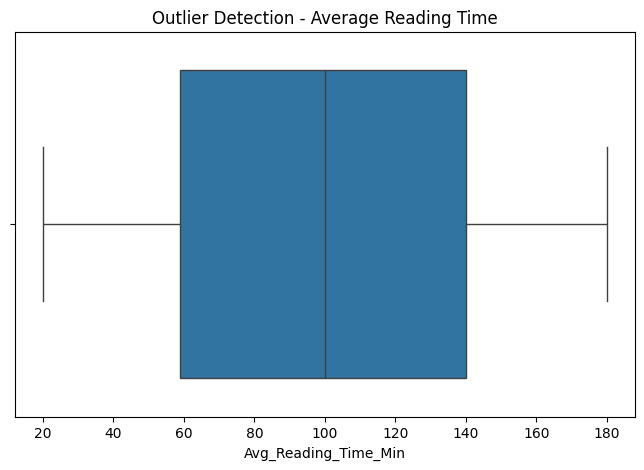

In [10]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='Avg_Reading_Time_Min')

plt.title("Outlier Detection - Average Reading Time")
plt.show()

In [11]:
print("Final Dataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nFinal Dataset:")
display(df.head(10))

Final Dataset Shape:
(7800, 11)

Missing Values:
User_ID                  0
User_Type                0
Department               0
Academic_Level           0
Research_Area            0
Preferred_Language       0
Access_Frequency         0
Borrowing_Frequency      0
Avg_Reading_Time_Min     0
Device_Type              0
Recommendation_Status    0
dtype: int64

Duplicate Rows:
0

Final Dataset:


,User_ID,User_Type,Department,Academic_Level,Research_Area,Preferred_Language,Access_Frequency,Borrowing_Frequency,Avg_Reading_Time_Min,Device_Type,Recommendation_Status
0,U1000,Research Scholar,Civil,UG,Embedded Systems,English,High,Very Frequent,171,Desktop,Accepted
1,U1001,Library Staff,Chemistry,PG,Big Data,Tamil,Low,Occasional,21,Tablet,Accepted
2,U1002,Student,Physics,PhD,Cyber Security,Tamil,High,Frequent,63,Laptop,Accepted
3,U1003,Research Scholar,English,PhD,Big Data,Tamil,Low,Occasional,38,Mobile,Rejected
4,U1004,Research Scholar,Mechanical,UG,Software Engineering,Tamil,High,Occasional,171,Laptop,Rejected
5,U1005,Library Staff,Biotechnology,PG,IoT,Tamil,High,Rare,69,Mobile,Rejected
6,U1006,Student,English,UG,Robotics,English,High,Frequent,39,Laptop,Rejected
7,U1007,Student,Management,PG,Cyber Security,Hindi,Low,Frequent,76,Laptop,Rejected
8,U1008,Research Scholar,Mathematics,PhD,Machine Learning,Hindi,High,Frequent,132,Mobile,Accepted
9,U1009,Faculty,English,UG,Software Engineering,English,Low,Frequent,69,Tablet,Rejected


In [16]:
# Save cleaned dataset
df.to_csv('library_literature_cleaned.csv', index=False)

print("Cleaned Dataset Saved Successfully!")

# Download cleaned file
from google.colab import files
files.download('library_literature_cleaned.csv')

Cleaned Dataset Saved Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>